<a href="https://colab.research.google.com/github/meetmehedi/Fraud-Detection-with-DistilBERT-A-Transformer-Based-Approach-to-Behavioral-Banking-Sequences/blob/main/fraud_clean.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fraud Detection: clean end-to-end pipeline

Dataset: `Phoenix21/mock_fraud-detection-dataset` (transactions with `user_id`, `timestamp`, `amount`, `description`, `is_fraud`).

**Run top to bottom in Google Colab** (Runtime → Change runtime type → GPU).

| Part | What it does |
|---|---|
| 1 | Load + explore the data |
| A | User-level Random Forest: RFM only vs NLP only vs RFM + NLP |
| B | Transaction-level text models: Logistic Regression, SVM, Random Forest (TF-IDF), LSTM, GRU, DistilBERT |
| 3 | Compare all models (table + ROC curves) |
| 4 | **Save every model** into `fraud_artifacts/` and download a zip |
| 5 | Reload the saved files and test them |

Fixes versus the old notebook: stratified train/val/test splits, TF-IDF fitted on training data only (no leakage), class weights for the rare fraud class, decision thresholds chosen on validation data, DistilBERT in PyTorch with attention masks, and everything saved to disk.

In [1]:
!pip install -q transformers accelerate scikit-learn joblib pandas matplotlib

In [2]:
import os, json, shutil, warnings
os.environ["USE_TF"] = "0"               # transformers: PyTorch only (avoids TF / Keras 3 clashes)
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
import torch
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, f1_score, fbeta_score,
                             precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from transformers import (DataCollatorWithPadding, DistilBertForSequenceClassification,
                          DistilBertTokenizerFast, Trainer, TrainingArguments)

SEED = 42
OUT = "fraud_artifacts"
os.makedirs(OUT, exist_ok=True)
np.random.seed(SEED)
torch.manual_seed(SEED)
tf.keras.utils.set_random_seed(SEED)

DATA_URL = "hf://datasets/Phoenix21/mock_fraud-detection-dataset/transactions.csv"
print("GPU available:", torch.cuda.is_available())

GPU available: True


## 1. Load and explore the data

Shape: (34767, 11)
Columns: ['transaction_id', 'user_id', 'timestamp', 'amount', 'merchant', 'description', 'transaction_type', 'device', 'ip_address', 'location', 'is_fraud']

Missing values:
 transaction_id          0
user_id                 0
timestamp               0
amount                  0
merchant                0
description             0
transaction_type        0
device                  0
ip_address          10041
location                0
is_fraud                0
dtype: int64

Fraud rate: 10.1936%


,transaction_id,user_id,timestamp,amount,merchant,description,transaction_type,device,ip_address,location,is_fraud
0,T0000000000,U00000000,2025-03-13 19:49:34,242.02,"Johnson, Moore and Dixon Hardware",Cash withdrawal,withdrawal,mobile,204.21.94.61,"Sarahfort, DE",0
1,T0000000001,U00000000,2025-02-28 17:42:01,793.26,Cooper-Archer Water Services,Subscription renewal - Cooper-Archer Water Ser...,subscription,pos,NaN,"Port Regina, DE",0
2,T0000000002,U00000000,2025-01-06 04:03:51,458.24,"Smith, Williams and Green Gas Company","Monthly subscription - Smith, Williams and Gre...",subscription,web,72.78.109.157,"Edwardsfurt, DE",0
3,T0000000003,U00000000,2025-03-06 12:13:41,420.79,Acosta-Harvey Investments,Bank withdrawal,withdrawal,web,51.168.205.46,"East Austin, DE",0
4,T0000000004,U00000000,2025-03-04 11:27:56,647.34,"Smith, Williams and Green Gas Company","Purchase at Smith, Williams and Green Gas Company",purchase,mobile,109.49.153.11,"Lake Johnbury, DE",0


,timestamp,amount,is_fraud
count,34767,34767.000000,34767.000000
mean,2025-02-12 22:07:00.614720768,512.219602,0.101936
min,2024-05-11 01:18:29,0.510000,0.000000
25%,2025-02-01 08:38:57,134.250000,0.000000
50%,2025-02-21 20:08:17,282.160000,0.000000
75%,2025-03-06 03:47:47,572.910000,0.000000
max,2025-03-14 22:26:37,12406.140000,1.000000
std,NaN,771.968341,0.302568


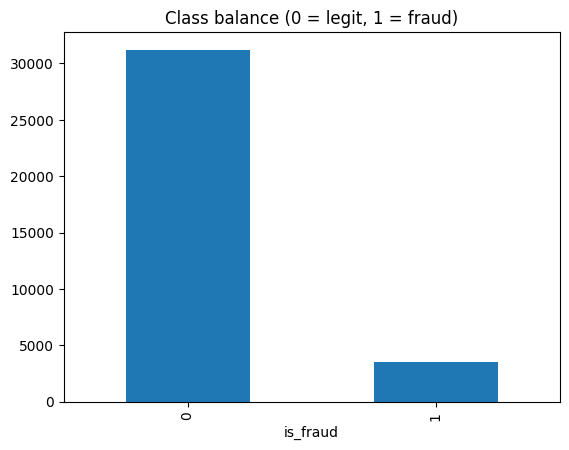

In [3]:
df = pd.read_csv(DATA_URL)
df["timestamp"] = pd.to_datetime(df["timestamp"])
df["description"] = df["description"].fillna("").astype(str)
df["is_fraud"] = df["is_fraud"].astype(int)

print("Shape:", df.shape)
print("Columns:", list(df.columns))
print("\nMissing values:\n", df.isnull().sum())
print(f"\nFraud rate: {df['is_fraud'].mean():.4%}")
display(df.head())
display(df.describe())
df["is_fraud"].value_counts().plot.bar(title="Class balance (0 = legit, 1 = fraud)")
plt.show()

## 2. Part A: user-level model (RFM vs NLP vs RFM + NLP)

One row per user. **Recency** = days since last transaction, **Frequency** = number of transactions, **Monetary** = total amount.
A user is labelled fraud if *any* of their transactions is fraud. Users are split first, and TF-IDF is fitted on training users only.

In [4]:
snapshot = df["timestamp"].max()
users = df.groupby("user_id").agg(
    last_ts=("timestamp", "max"),
    Frequency=("transaction_id", "count"),
    Monetary=("amount", "sum"),
    text=("description", " ".join),
    is_fraud=("is_fraud", "max"),
).reset_index()
users["Recency"] = (snapshot - users["last_ts"]).dt.days
RFM_COLS = ["Recency", "Frequency", "Monetary"]

print(users["is_fraud"].value_counts())
strat = users["is_fraud"] if users["is_fraud"].value_counts().min() >= 2 else None
u_train, u_test = train_test_split(users, test_size=0.3, stratify=strat, random_state=SEED)
print("train users:", len(u_train), " test users:", len(u_test))

is_fraud
1    839
0    161
Name: count, dtype: int64
train users: 700  test users: 300


In [5]:
def make_rf():
    return RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                  random_state=SEED, n_jobs=-1)

def make_tfidf():
    return TfidfVectorizer(stop_words="english", max_features=1000)

user_models = {
    "RFM only": Pipeline([("prep", ColumnTransformer([("rfm", "passthrough", RFM_COLS)])),
                          ("rf", make_rf())]),
    "NLP only": Pipeline([("prep", ColumnTransformer([("tfidf", make_tfidf(), "text")])),
                          ("rf", make_rf())]),
    "RFM + NLP": Pipeline([("prep", ColumnTransformer([("rfm", "passthrough", RFM_COLS),
                                                       ("tfidf", make_tfidf(), "text")])),
                           ("rf", make_rf())]),
}

user_results = {}
for name, pipe in user_models.items():
    pipe.fit(u_train, u_train["is_fraud"])
    pred = pipe.predict(u_test)
    prob = pipe.predict_proba(u_test)[:, 1]
    both = u_test["is_fraud"].nunique() == 2
    user_results[name] = {
        "f1": float(f1_score(u_test["is_fraud"], pred, zero_division=0)),
        "roc_auc": float(roc_auc_score(u_test["is_fraud"], prob)) if both else None,
    }
    print(f"=== {name} ===")
    print(classification_report(u_test["is_fraud"], pred, zero_division=0))

pd.DataFrame(user_results).T.round(4)

=== RFM only ===
              precision    recall  f1-score   support

           0       0.58      0.44      0.50        48
           1       0.90      0.94      0.92       252

    accuracy                           0.86       300
   macro avg       0.74      0.69      0.71       300
weighted avg       0.85      0.86      0.85       300

=== NLP only ===
              precision    recall  f1-score   support

           0       0.86      0.40      0.54        48
           1       0.90      0.99      0.94       252

    accuracy                           0.89       300
   macro avg       0.88      0.69      0.74       300
weighted avg       0.89      0.89      0.88       300

=== RFM + NLP ===
              precision    recall  f1-score   support

           0       0.87      0.42      0.56        48
           1       0.90      0.99      0.94       252

    accuracy                           0.90       300
   macro avg       0.88      0.70      0.75       300
weighted avg       0.8

,f1,roc_auc
RFM only,0.9186,0.8850
NLP only,0.9396,0.9145
RFM + NLP,0.9414,0.9226


## 3. Part B: transaction-level text models

Input is the transaction `description`. Stratified 80 / 10 / 10 split. The validation set is used **only** to choose each model's decision threshold; the test set is used **only** for the final scores.

In [6]:
data = df[["description", "is_fraud"]].copy()
train_val, test = train_test_split(data, test_size=0.10, stratify=data["is_fraud"], random_state=SEED)
train, val = train_test_split(train_val, test_size=0.1111, stratify=train_val["is_fraud"], random_state=SEED)
print(f"train={len(train)}  val={len(val)}  test={len(test)}")

results = {}      # test metrics per model
test_probs = {}   # test probabilities per model (for ROC curves)

def best_threshold(y_true, prob):
    """Threshold that maximises F1 on the validation set."""
    p, r, t = precision_recall_curve(y_true, prob)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-9, None)
    return float(t[int(np.argmax(f1))])

def evaluate(name, val_prob, test_prob):
    thr = best_threshold(val["is_fraud"], val_prob)
    pred = (test_prob >= thr).astype(int)
    y = test["is_fraud"]
    results[name] = {
        "threshold": thr,
        "f0.5": float(fbeta_score(y, pred, beta=0.5, zero_division=0)),
        "f1": float(f1_score(y, pred, zero_division=0)),
        "f2": float(fbeta_score(y, pred, beta=2, zero_division=0)),
        "roc_auc": float(roc_auc_score(y, test_prob)),
    }
    test_probs[name] = test_prob
    print(name, {k: round(v, 4) for k, v in results[name].items()})

train=27813  val=3477  test=3477


### 3.1 Classical models on TF-IDF (Logistic Regression, SVM, Random Forest)

In [7]:
def tfidf_text():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)

sk_models = {
    "Logistic Regression": Pipeline([("tfidf", tfidf_text()),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
    # LinearSVC is much faster than SVC(probability=True); calibration gives probabilities.
    "SVM": Pipeline([("tfidf", tfidf_text()),
        ("clf", CalibratedClassifierCV(LinearSVC(class_weight="balanced"), cv=3))]),
    "Random Forest": Pipeline([("tfidf", tfidf_text()),
        ("clf", RandomForestClassifier(n_estimators=100, class_weight="balanced",
                                       n_jobs=-1, random_state=SEED))]),
}

for name, pipe in sk_models.items():
    pipe.fit(train["description"], train["is_fraud"])
    evaluate(name,
             pipe.predict_proba(val["description"])[:, 1],
             pipe.predict_proba(test["description"])[:, 1])

Logistic Regression {'threshold': 0.5128, 'f0.5': 0.2214, 'f1': 0.2318, 'f2': 0.2432, 'roc_auc': 0.6007}
SVM {'threshold': 0.1477, 'f0.5': 0.2722, 'f1': 0.2305, 'f2': 0.1999, 'roc_auc': 0.6003}
Random Forest {'threshold': 0.07, 'f0.5': 0.1445, 'f1': 0.2108, 'f2': 0.3894, 'roc_auc': 0.5915}


### 3.2 LSTM and GRU (the text vectorizer is part of the model, so the saved file is self-contained)

In [8]:
MAX_TOKENS, MAX_LEN, BATCH = 20000, 100, 64

def to_ds(frame, labels=True, shuffle=False):
    x = frame["description"].values
    ds = tf.data.Dataset.from_tensor_slices((x, frame["is_fraud"].values) if labels else x)
    if shuffle:
        ds = ds.shuffle(len(frame), seed=SEED)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

def build_rnn(rnn_layer):
    vec = tf.keras.layers.TextVectorization(max_tokens=MAX_TOKENS, output_sequence_length=MAX_LEN)
    vec.adapt(tf.data.Dataset.from_tensor_slices(train["description"].values).batch(512))
    inp = tf.keras.Input(shape=(), dtype=tf.string)
    x = vec(inp)
    x = tf.keras.layers.Embedding(MAX_TOKENS, 128, mask_zero=True)(x)
    x = rnn_layer(64)(x)
    x = tf.keras.layers.Dropout(0.2)(x)
    out = tf.keras.layers.Dense(1, activation="sigmoid")(x)
    model = tf.keras.Model(inp, out)
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model

w = len(train) / (2.0 * np.bincount(train["is_fraud"], minlength=2))
class_weight = {0: float(w[0]), 1: float(w[1])}

keras_models = {}
for name, layer in [("LSTM", tf.keras.layers.LSTM), ("GRU", tf.keras.layers.GRU)]:
    model = build_rnn(layer)
    model.fit(to_ds(train, shuffle=True), validation_data=to_ds(val), epochs=5,
              class_weight=class_weight, verbose=2,
              callbacks=[tf.keras.callbacks.EarlyStopping(patience=1, restore_best_weights=True)])
    keras_models[name] = model
    evaluate(name,
             model.predict(to_ds(val, labels=False), verbose=0).ravel(),
             model.predict(to_ds(test, labels=False), verbose=0).ravel())

Epoch 1/5
435/435 - 13s - 30ms/step - accuracy: 0.6984 - loss: 0.6686 - val_accuracy: 0.7737 - val_loss: 0.6347
Epoch 2/5
435/435 - 3s - 8ms/step - accuracy: 0.7673 - loss: 0.5785 - val_accuracy: 0.6776 - val_loss: 0.6681
LSTM {'threshold': 0.5809, 'f0.5': 0.296, 'f1': 0.1784, 'f2': 0.1277, 'roc_auc': 0.5712}
Epoch 1/5
435/435 - 5s - 11ms/step - accuracy: 0.6653 - loss: 0.6689 - val_accuracy: 0.7489 - val_loss: 0.6292
Epoch 2/5
435/435 - 4s - 10ms/step - accuracy: 0.7685 - loss: 0.5645 - val_accuracy: 0.7366 - val_loss: 0.6243
Epoch 3/5
435/435 - 4s - 10ms/step - accuracy: 0.7952 - loss: 0.4379 - val_accuracy: 0.7167 - val_loss: 0.6311
GRU {'threshold': 0.5534, 'f0.5': 0.2239, 'f1': 0.2612, 'f2': 0.3134, 'roc_auc': 0.6486}


### 3.3 DistilBERT (PyTorch, class-weighted loss, attention masks)

In [9]:
bert_tok = DistilBertTokenizerFast.from_pretrained("distilbert-base-uncased")

class TxtDataset(torch.utils.data.Dataset):
    def __init__(self, frame):
        self.enc = bert_tok(list(frame["description"]), truncation=True, max_length=128)
        self.labels = list(frame["is_fraud"])
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}   # input_ids + attention_mask
        item["labels"] = self.labels[i]
        return item

torch_w = torch.tensor(w, dtype=torch.float)

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss = torch.nn.functional.cross_entropy(outputs.logits, labels,
                                                 weight=torch_w.to(outputs.logits.device))
        return (loss, outputs) if return_outputs else loss

bert_model = DistilBertForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=2)
trainer = WeightedTrainer(
    model=bert_model,
    args=TrainingArguments(output_dir="bert_runs", num_train_epochs=2,
                           per_device_train_batch_size=16, per_device_eval_batch_size=64,
                           learning_rate=5e-5, fp16=torch.cuda.is_available(),
                           save_strategy="no", report_to="none", seed=SEED),
    train_dataset=TxtDataset(train),
    data_collator=DataCollatorWithPadding(bert_tok),
)
trainer.train()

def bert_prob(frame):
    logits = trainer.predict(TxtDataset(frame)).predictions
    return torch.softmax(torch.tensor(logits), dim=1)[:, 1].numpy()

evaluate("DistilBERT", bert_prob(val), bert_prob(test))

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
500,0.674789
1000,0.648572
1500,0.655775
2000,0.645775
2500,0.645084
3000,0.640209


DistilBERT {'threshold': 0.4376, 'f0.5': 0.2819, 'f1': 0.1751, 'f2': 0.127, 'roc_auc': 0.5418}


## 4. Compare all models

,threshold,f0.5,f1,f2,roc_auc
GRU,0.5534,0.2239,0.2612,0.3134,0.6486
Logistic Regression,0.5128,0.2214,0.2318,0.2432,0.6007
SVM,0.1477,0.2722,0.2305,0.1999,0.6003
Random Forest,0.0700,0.1445,0.2108,0.3894,0.5915
LSTM,0.5809,0.2960,0.1784,0.1277,0.5712
DistilBERT,0.4376,0.2819,0.1751,0.1270,0.5418


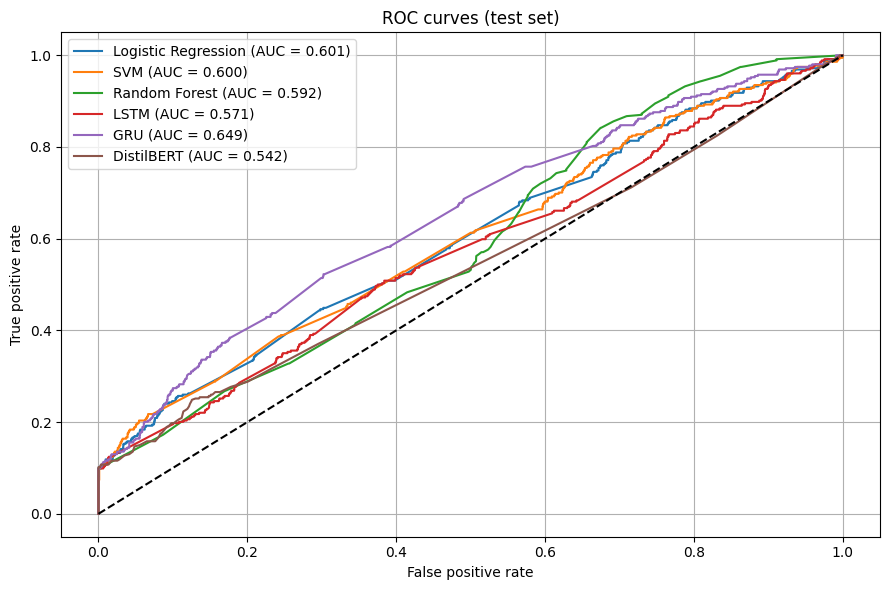

In [10]:
summary = pd.DataFrame(results).T.sort_values("f1", ascending=False).round(4)
display(summary)

plt.figure(figsize=(9, 6))
for name, prob in test_probs.items():
    fpr, tpr, _ = roc_curve(test["is_fraud"], prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {results[name]['roc_auc']:.3f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves (test set)"); plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig(f"{OUT}/roc_curves.png", dpi=150)
plt.show()

## 5. Save everything

Colab's disk is wiped when the runtime resets, so this cell writes all artifacts and downloads a zip.

In [11]:
# sklearn pipelines (vectorizer + classifier saved together)
joblib.dump(user_models["RFM + NLP"], f"{OUT}/user_rfm_nlp_rf.joblib", compress=3)
for name, pipe in sk_models.items():
    joblib.dump(pipe, f"{OUT}/{name.lower().replace(' ', '_')}.joblib", compress=3)

# Keras models (include their TextVectorization layer)
for name, model in keras_models.items():
    model.save(f"{OUT}/{name.lower()}.keras")

# DistilBERT: weights + config + tokenizer
trainer.save_model(f"{OUT}/distilbert")
bert_tok.save_pretrained(f"{OUT}/distilbert")

# Scores and thresholds
with open(f"{OUT}/metrics.json", "w") as f:
    json.dump({"text_models": results, "user_models": user_results}, f, indent=2)

shutil.make_archive(OUT, "zip", OUT)
for root, _, files in os.walk(OUT):
    for fn in files:
        p = os.path.join(root, fn)
        print(f"{p:60s} {os.path.getsize(p) / 1e6:8.1f} MB")

try:
    from google.colab import files
    files.download(f"{OUT}.zip")
except ImportError:
    pass

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

fraud_artifacts/logistic_regression.joblib                        0.2 MB
fraud_artifacts/metrics.json                                      0.0 MB
fraud_artifacts/lstm.keras                                       31.5 MB
fraud_artifacts/user_rfm_nlp_rf.joblib                            0.8 MB
fraud_artifacts/gru.keras                                        31.3 MB
fraud_artifacts/random_forest.joblib                             14.6 MB
fraud_artifacts/svm.joblib                                        0.3 MB
fraud_artifacts/roc_curves.png                                    0.2 MB
fraud_artifacts/distilbert/training_args.bin                      0.0 MB
fraud_artifacts/distilbert/model.safetensors                    267.8 MB
fraud_artifacts/distilbert/tokenizer_config.json                  0.0 MB
fraud_artifacts/distilbert/tokenizer.json                         0.7 MB
fraud_artifacts/distilbert/config.json                            0.0 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. Reload the saved files and test them

In [12]:
lr_loaded = joblib.load(f"{OUT}/logistic_regression.joblib")
lstm_loaded = tf.keras.models.load_model(f"{OUT}/lstm.keras")
bert_loaded = DistilBertForSequenceClassification.from_pretrained(f"{OUT}/distilbert").eval()
bert_tok_loaded = DistilBertTokenizerFast.from_pretrained(f"{OUT}/distilbert")

samples = test.head(3)
for text, label in zip(samples["description"], samples["is_fraud"]):
    p_lr = lr_loaded.predict_proba([text])[0, 1]
    p_lstm = float(lstm_loaded.predict(tf.constant([text]), verbose=0)[0, 0])
    enc = bert_tok_loaded(text, truncation=True, max_length=128, return_tensors="pt")
    with torch.no_grad():
        p_bert = float(torch.softmax(bert_loaded(**enc).logits, dim=1)[0, 1])
    print(f"true={label} | LogReg={p_lr:.3f} | LSTM={p_lstm:.3f} | DistilBERT={p_bert:.3f} | {text[:70]}")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

true=0 | LogReg=0.425 | LSTM=0.466 | DistilBERT=0.433 | Shopping at Parker, Lopez and Wilson Bistro
true=0 | LogReg=0.474 | LSTM=0.454 | DistilBERT=0.433 | Bank withdrawal
true=0 | LogReg=0.474 | LSTM=0.454 | DistilBERT=0.433 | Bank withdrawal
